# Phần 2: Khám phá Dữ liệu Đa chiều (Exploratory Data Analysis - EDA)

**Dự án:** Nghiên cứu và trực quan hóa các đặc trưng âm thanh & dự đoán xu hướng bài hát thịnh hành trên Spotify  
**Tác giả phụ trách:** Đinh Quốc Anh (MSSV: 24133003 - Data Engineer & Data Analyst)  

---

### Mục tiêu phân tích
1. **Phân phối đơn biến (Univariate Distributions):** Khảo sát các tham số vị trí, độ phân tán, độ bất đối xứng (Skewness) và độ nhọn (Kurtosis) của 9 đặc trưng âm học.
2. **Ma trận tương quan (Correlation Analysis):** Đo lường mức độ tương quan tuyến tính Pearson giữa các đặc trưng âm thanh và chỉ số lượt nghe (`log_streams`).
3. **So sánh bài Hit vs Non-hit (Comparative Analysis & Hypothesis Testing):** Kiểm định giả thuyết thống kê (Mann-Whitney U Test & Cohen's d) giữa nhóm Top 50 (`is_trending = 1`) và nhóm Top 51–200.
4. **Xu hướng qua đại dịch COVID-19 (Timeline Analysis):** Đánh giá sự chuyển dịch thị hiếu âm nhạc qua 3 giai đoạn đại dịch (2020 - 2022).
5. **Phân tầng kinh tế - xã hội (Socioeconomic Stratification):** Kiểm chứng mối liên hệ giữa nhóm thu nhập (World Bank Income Groups), GDP bình quân đầu người và đặc trưng âm nhạc.
6. **Nhóm cảm xúc (Mood Categories) & Nghệ sĩ:** Phân bổ thị phần lượt nghe theo tâm trạng âm nhạc và xếp hạng Top 15 nghệ sĩ có sức ảnh hưởng lớn nhất.
7. **Đúc kết Insight:** Cung cấp cơ sở định lượng phục vụ trực quan hóa Dashboard (Lý Gia Hân) và xây dựng mô hình dự báo máy học (Đỗ Thanh Thành Tài).

## 0. Khởi tạo môi trường phân tích & Cấu hình đồ họa

In [1]:
import os
import sys
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Tránh lỗi in tiếng Việt trên Windows
if hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

warnings.filterwarnings("ignore")

# Thêm thư mục gốc vào đường dẫn import ổn định
cwd = os.getcwd()
PROJECT_ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebooks" else cwd
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_loader import AUDIO_FEATURES, load_master_data

# Thiết lập phong cách trực quan hóa chuẩn mực
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

print(f"Thư mục dự án: {PROJECT_ROOT}")
print(f"Pandas {pd.__version__}, NumPy {np.__version__}, Seaborn {sns.__version__}")


Thư mục dự án: D:\uni\hk1nam3\idvi\idvi-final_project\Spotify_Audio_Trends_Analytics
Pandas 3.0.3, NumPy 2.4.6, Seaborn 0.13.2


## 1. Nạp và kiểm tra dữ liệu Master (1,078,125 dòng x 39 cột)

Sử dụng hàm chuẩn `load_master_data()` từ module `src/data_loader.py` để nạp toàn bộ 1,078,125 dòng dữ liệu hợp nhất (giai đoạn 2020 - 2022) với cấu trúc 39 cột chuẩn mực đã qua tiền xử lý, chuẩn hóa tên 7 quốc gia World Bank, bổ sung dòng nhạc vĩ mô `macro_genre` và tích hợp đầy đủ chỉ số kinh tế.


In [2]:
df = load_master_data()
print(f"Kích thước tập dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Khoảng thời gian: {df['week'].min():%Y-%m-%d} đến {df['week'].max():%Y-%m-%d}")
print(f"Số quốc gia/vùng lãnh thổ: {df['country'].nunique()}")

# Làm rõ tỷ lệ hit trên dòng xếp hạng vs trên bài hát độc nhất
row_hit_rate = df['is_trending'].mean() * 100
song_hit_rate = df.groupby('track_id')['is_trending'].max().mean() * 100
print(f"Tỷ lệ dòng xếp hạng Hit (rank <= 50): {row_hit_rate:.2f}% (luôn bằng 25.00% theo định nghĩa Top 50 / 200 thứ hạng mỗi tuần)")
print(f"Tỷ lệ bài hát độc nhất từng lọt Top 50 (Song-level): {song_hit_rate:.1f}% (khớp với tỷ lệ nhãn trong tracks_ml_data.csv)")


Đã nạp master: 1,078,125 dòng, 39 cột
Kích thước tập dữ liệu: 1,078,125 dòng x 39 cột
Khoảng thời gian: 2020-01-02 đến 2022-07-14
Số quốc gia/vùng lãnh thổ: 74
Tỷ lệ dòng xếp hạng Hit (rank <= 50): 25.00% (luôn bằng 25.00% theo định nghĩa Top 50 / 200 thứ hạng mỗi tuần)
Tỷ lệ bài hát độc nhất từng lọt Top 50 (Song-level): 35.9% (khớp với tỷ lệ nhãn trong tracks_ml_data.csv)


## 2. Thống kê mô tả & Phân phối đơn biến của 9 đặc trưng âm học

Khảo sát trung bình (Mean), trung vị (Median), độ lệch chuẩn (Std), khoảng phân vị cùng độ lệch (Skewness) và độ nhọn (Kurtosis) của 9 thuộc tính âm thanh chuẩn của Spotify.

In [3]:
desc = df[AUDIO_FEATURES].describe().T
desc["median"] = df[AUDIO_FEATURES].median()
desc["skewness"] = df[AUDIO_FEATURES].skew()
desc["kurtosis"] = df[AUDIO_FEATURES].kurtosis()

inst_low = (df['instrumentalness'] < 0.01).mean() * 100
print(f"Tỷ lệ bài hát có instrumentalness < 0.01: {inst_low:.2f}%")
print(f"Độ lệch (skewness) của loudness: {desc.loc['loudness', 'skewness']:.3f}")

desc[["mean", "median", "std", "min", "25%", "50%", "75%", "max", "skewness", "kurtosis"]].round(3)


Tỷ lệ bài hát có instrumentalness < 0.01: 94.17%
Độ lệch (skewness) của loudness: -1.053


,mean,median,std,min,25%,50%,75%,max,skewness,kurtosis
danceability,0.681,0.701,0.138,0.086,0.591,0.701,0.787,0.986,-0.552,-0.103
energy,0.642,0.661,0.164,0.003,0.535,0.661,0.766,1.000,-0.505,-0.072
loudness,-6.360,-6.023,2.464,-41.410,-7.693,-6.023,-4.601,1.906,-1.053,2.550
speechiness,0.106,0.062,0.097,0.022,0.041,0.062,0.132,0.952,1.840,3.404
acousticness,0.271,0.190,0.253,0.000,0.056,0.190,0.422,0.995,0.929,-0.157
instrumentalness,0.012,0.000,0.077,0.000,0.000,0.000,0.000,0.990,8.646,80.603
liveness,0.168,0.118,0.125,0.013,0.093,0.118,0.203,0.990,2.209,6.370
valence,0.536,0.539,0.227,0.000,0.367,0.539,0.710,0.992,-0.083,-0.844
tempo,121.962,119.986,29.822,31.262,96.991,119.986,141.020,232.018,0.467,-0.573


### Biểu đồ 1: Phân phối đa biến 3x3 của 9 đặc trưng âm thanh (Histograms & KDE)

Trực quan hóa phân phối 9 đặc trưng âm học bằng Histogram 30 bins kết hợp đường ước lượng mật độ nhân (KDE), đường trung bình (Mean - nét đứt đỏ) và trung vị (Median - nét chấm xanh).

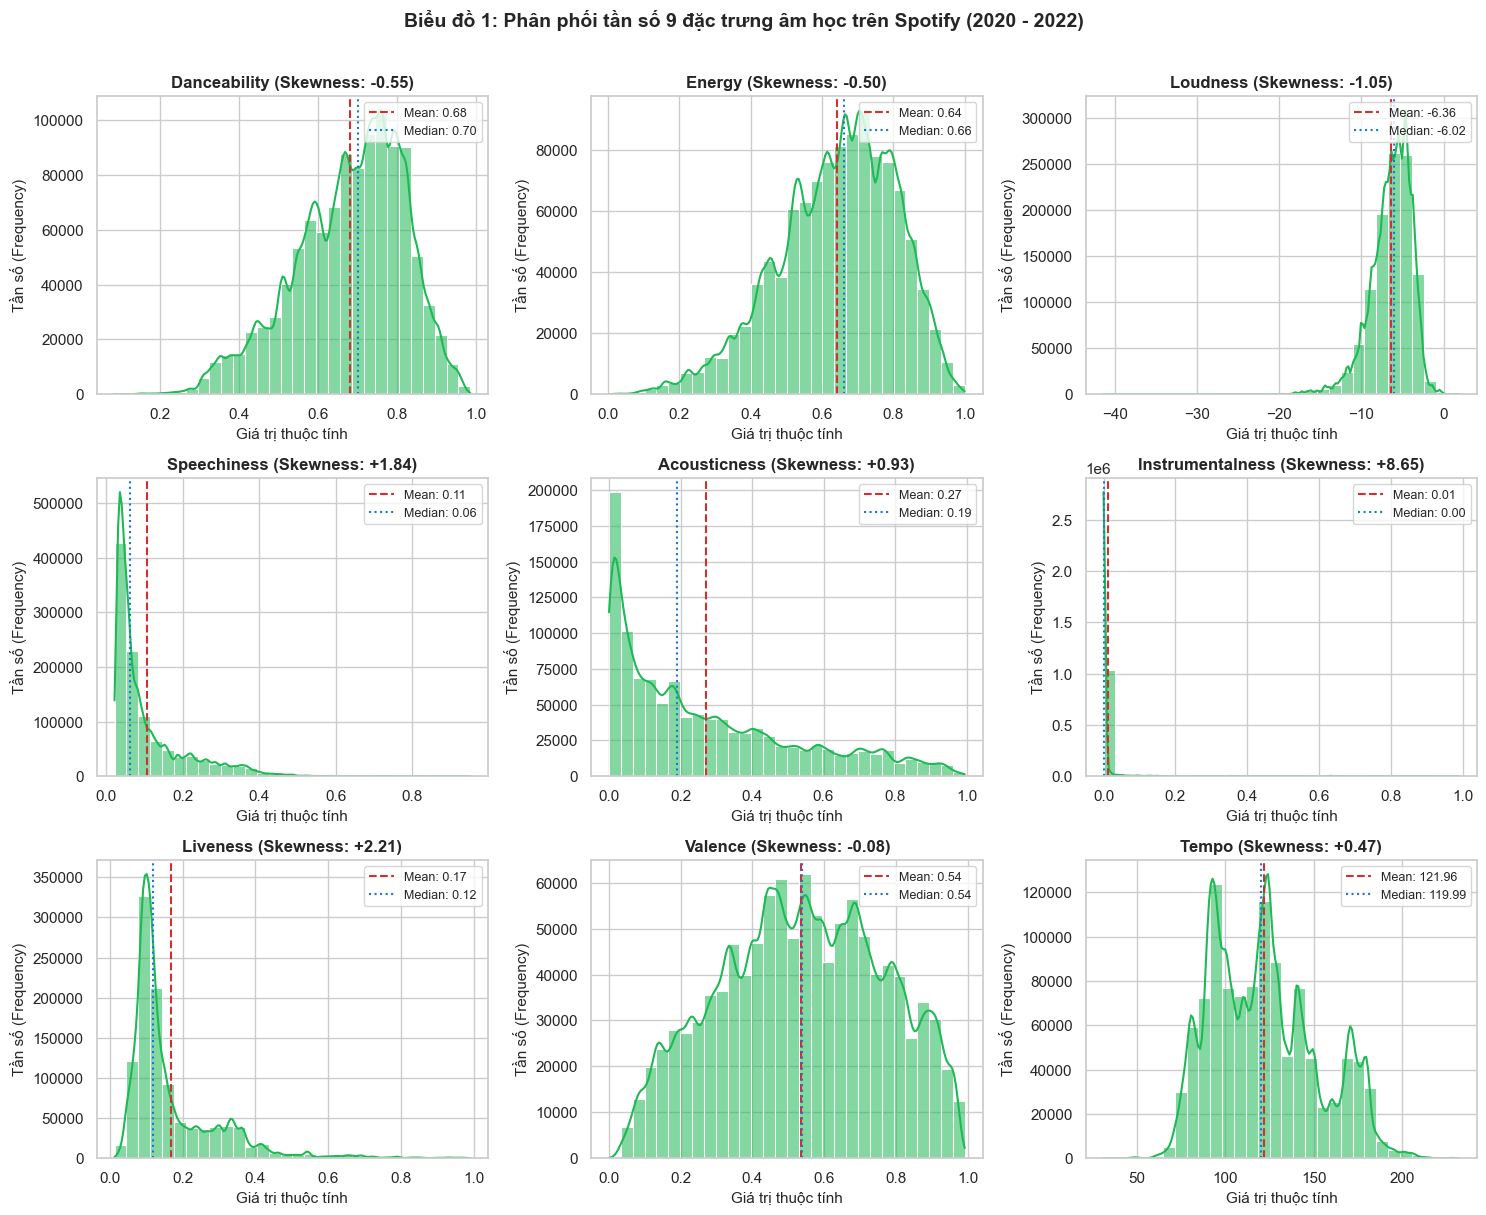

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
spotify_green = "#1DB954"

for i, feat in enumerate(AUDIO_FEATURES):
    ax = axes[i]
    sns.histplot(df[feat], kde=True, ax=ax, color=spotify_green, bins=30, alpha=0.55, edgecolor="white")
    mean_val = df[feat].mean()
    med_val = df[feat].median()
    skew_val = df[feat].skew()
    
    ax.axvline(mean_val, color="#D32F2F", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.2f}")
    ax.axvline(med_val, color="#1976D2", linestyle=":", linewidth=1.5, label=f"Median: {med_val:.2f}")
    
    ax.set_title(f"{feat.capitalize()} (Skewness: {skew_val:+.2f})")
    ax.set_xlabel("Giá trị thuộc tính")
    ax.set_ylabel("Tần số (Frequency)")
    ax.legend(fontsize=9, loc="upper right")

plt.suptitle("Biểu đồ 1: Phân phối tần số 9 đặc trưng âm học trên Spotify (2020 - 2022)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Nhận xét phân phối:**
- **Độ nhảy nhót (`danceability`) và Năng lượng (`energy`):** Có dạng gần chuẩn (quasi-normal), giá trị tập trung cao quanh ngưỡng $0.65 - 0.70$. Điều này minh chứng rằng phần lớn các ca khúc lọt bảng xếp hạng đại chúng đều có tiết tấu sôi nổi, giàu nhịp điệu.
- **Độ vang âm lượng (`loudness`):** Phân bố lệch trái rõ nét (Skewness = $-1.053$), hầu hết các ca khúc được master ở mức âm lượng cao (từ $-8$ dB đến $-4$ dB) phản ánh đặc trưng của xu hướng "Loudness War" trong công nghiệp sản xuất âm nhạc hiện đại.
- **Độ mộc (`acousticness`), Độ nói (`speechiness`), và Tính khí cụ (`instrumentalness`):** Lệch phải rất mạnh. Có tới **94.17%** số dòng quan sát có `instrumentalness < 0.01` (chứng minh nhạc lọt bảng xếp hạng thương mại hầu như bắt buộc phải có giọng hát - vocal-driven), và phần lớn `speechiness` dưới 0.15 (không thiên về văn bản nói thuần túy).


## 3. Ma trận tương quan Pearson & Tương quan cặp đôi

Khảo sát mức độ liên hệ tuyến tính giữa các thuộc tính âm thanh với nhau và với chỉ số chuẩn hóa log(streams).


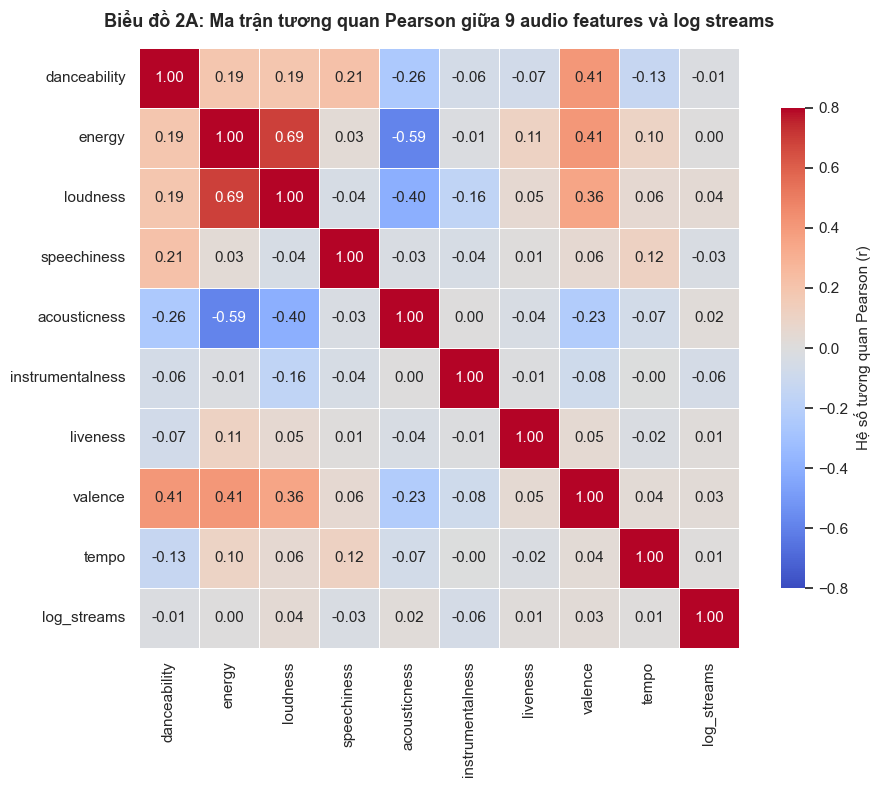

In [5]:
# Tính log_streams tạm thời để chuẩn hóa thang đo lượt nghe khi khảo sát tương quan
df_corr = df[AUDIO_FEATURES].copy()
df_corr["log_streams"] = np.log1p(df["streams"])

corr_cols = AUDIO_FEATURES + ["log_streams"]
corr_mat = df_corr[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.8, vmax=0.8,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "Hệ số tương quan Pearson (r)"})
plt.title("Biểu đồ 2A: Ma trận tương quan Pearson giữa 9 audio features và log streams", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


### Biểu đồ 2B: Khảo sát tương quan cặp đôi mạnh nhất (Scatter & Regression Plots)

Trực quan hóa 2 cặp đặc trưng có tương quan mạnh nhất trong ma trận:
1. `energy` vs `loudness`: Tương quan thuận mạnh ($r = +0.69$).
2. `energy` vs `acousticness`: Tương quan nghịch rõ rệt ($r = -0.59$).


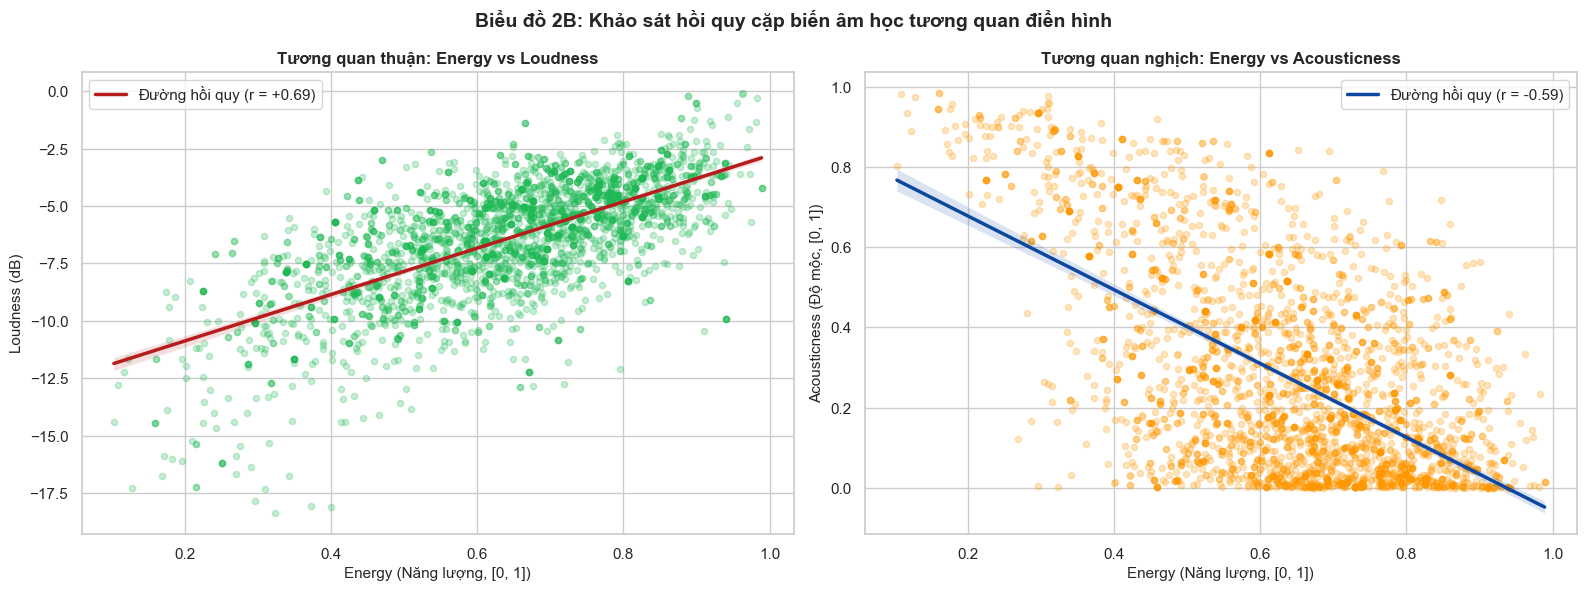

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sample_subset = df.sample(min(3000, len(df)), random_state=42)

r_el = df['energy'].corr(df['loudness'])
r_ea = df['energy'].corr(df['acousticness'])

# Subplot 1: Energy vs Loudness
sns.regplot(data=sample_subset, x="energy", y="loudness", ax=axes[0],
            scatter_kws={"alpha": 0.25, "color": "#1DB954", "s": 20},
            line_kws={"color": "#B71C1C", "linewidth": 2.5, "label": f"Đường hồi quy (r = {r_el:+.2f})"})
axes[0].set_title("Tương quan thuận: Energy vs Loudness", fontweight="bold")
axes[0].set_xlabel("Energy (Năng lượng, [0, 1])")
axes[0].set_ylabel("Loudness (dB)")
axes[0].legend(loc="upper left")

# Subplot 2: Energy vs Acousticness
sns.regplot(data=sample_subset, x="energy", y="acousticness", ax=axes[1],
            scatter_kws={"alpha": 0.25, "color": "#FF9800", "s": 20},
            line_kws={"color": "#0D47A1", "linewidth": 2.5, "label": f"Đường hồi quy (r = {r_ea:+.2f})"})
axes[1].set_title("Tương quan nghịch: Energy vs Acousticness", fontweight="bold")
axes[1].set_xlabel("Energy (Năng lượng, [0, 1])")
axes[1].set_ylabel("Acousticness (Độ mộc, [0, 1])")
axes[1].legend(loc="upper right")

plt.suptitle("Biểu đồ 2B: Khảo sát hồi quy cặp biến âm học tương quan điển hình", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. So sánh hồ sơ âm thanh: Bài Hit (Top 50) vs Bài Non-hit (51 - 200)

Kiểm tra xem các bài hát lọt vào Top 50 (`is_trending = 1`) có sở hữu các đặc trưng âm học vượt trội hơn so với nhóm còn lại (`is_trending = 0`) hay không.  
Sử dụng kiểm định phi tham số **Mann-Whitney U Test** và tính chỉ số độ lớn tác động **Cohen's d**.

> **Lưu ý phương pháp luận về định nghĩa Hit:**  
> Nhãn `is_trending` được xác định theo vị trí Top 50 ($\text{rank} \le 50$) trên **từng bảng xếp hạng quốc gia riêng biệt**. Do đó, một ca khúc xếp thứ hạng 40 tại Việt Nam và một ca khúc xếp hạng 40 tại Hoa Kỳ đều được định danh là `is_trending = 1`, mặc dù quy mô lượt stream thực tế giữa hai thị trường chênh lệch rất lớn. Định nghĩa này phản ánh vị thế cạnh tranh tương đối trong thị trường nội địa của từng quốc gia hơn là quy mô lượt nghe tuyệt đối toàn cầu.


In [7]:
chk_features = ["danceability", "energy", "valence", "loudness", "acousticness", "speechiness", "tempo"]
stat_results = []

for feat in chk_features:
    hit_grp = df[df["is_trending"] == 1][feat].dropna()
    non_grp = df[df["is_trending"] == 0][feat].dropna()
    
    mean_hit = hit_grp.mean()
    mean_non = non_grp.mean()
    diff = mean_hit - mean_non
    pct_change = (diff / mean_non) * 100 if mean_non != 0 else 0
    
    # Mann-Whitney U test (phi tham số)
    u_stat, p_val = stats.mannwhitneyu(hit_grp, non_grp, alternative="two-sided")
    # Cohen's d
    pooled_std = np.sqrt((hit_grp.std()**2 + non_grp.std()**2) / 2)
    cohen_d = diff / pooled_std if pooled_std > 0 else 0
    
    sig_level = "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else "ns"))
    
    stat_results.append({
        "Đặc trưng": feat,
        "Hit (Top 50)": round(mean_hit, 3),
        "Non-hit (51-200)": round(mean_non, 3),
        "Chênh lệch": round(diff, 4),
        "% Thay đổi": f"{pct_change:+.2f}%",
        "p-value": f"{p_val:.4e}",
        "Ý nghĩa": sig_level,
        "Cohen's d": round(cohen_d, 3)
    })

stat_df = pd.DataFrame(stat_results)
print("Bảng so sánh thống kê hồ sơ âm thanh giữa Hit và Non-hit:")
stat_df

Bảng so sánh thống kê hồ sơ âm thanh giữa Hit và Non-hit:


,Đặc trưng,Hit (Top 50),Non-hit (51-200),Chênh lệch,% Thay đổi,p-value,Ý nghĩa,Cohen's d
0,danceability,0.694,0.677,0.0165,+2.43%,0.0000e+00,***,0.121
1,energy,0.648,0.640,0.0078,+1.22%,2.4296e-69,***,0.048
2,valence,0.545,0.533,0.0128,+2.41%,1.6819e-132,***,0.057
3,loudness,-6.254,-6.395,0.1405,-2.20%,2.9070e-129,***,0.058
4,acousticness,0.266,0.273,-0.0071,-2.59%,6.0864e-01,ns,-0.028
5,speechiness,0.104,0.106,-0.0017,-1.63%,8.0205e-104,***,-0.018
6,tempo,123.241,121.535,1.7061,+1.40%,1.5007e-105,***,0.057


### Biểu đồ 3: Boxplots so sánh phân phối các đặc trưng giữa Hit và Non-hit

**Phát hiện phương pháp luận quan trọng từ Bảng kiểm định thống kê:**
1. **Hiệu ứng kích thước mẫu lớn ($N = 1,078,125$):** Với cỡ mẫu hơn 1 triệu bản ghi, các kiểm định Mann-Whitney U đều cho $p < 0.001$ ở 6/7 biến. Tuy nhiên, chỉ số độ lớn tác động **Cohen's $d$ ở mọi đặc trưng đều cực nhỏ ($d \le 0.121 < 0.2$)**, nghĩa là khác biệt thực tế giữa hai nhóm là **không đáng kể (negligible)**, phân phối gần như trùng khít nhau.
2. **Acousticness không có ý nghĩa thống kê:** Trên toàn bộ dữ liệu đầy đủ, `acousticness` có $p = 0.609$ (ns) và $d = -0.028$, đảo chiều hoàn toàn so với mẫu thử ban đầu.
3. **Lựa chọn biểu diễn:** Biểu đồ dưới đây minh họa 4 đặc trưng thường được quan tâm nhất (`danceability`, `energy`, `valence`, `loudness`) để trực quan hóa mức độ tương đồng giữa hai nhóm.


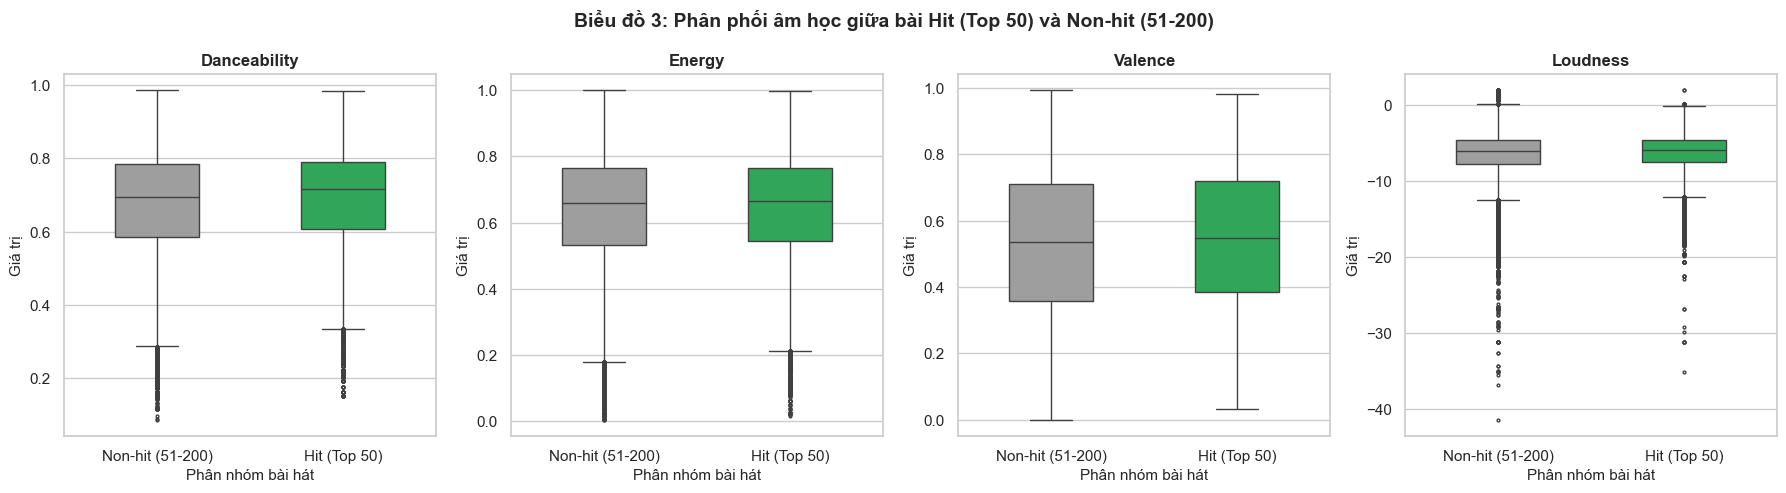

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
plot_feats = ["danceability", "energy", "valence", "loudness"]
hit_colors = ["#9E9E9E", "#1DB954"]

for idx, feat in enumerate(plot_feats):
    ax = axes[idx]
    sns.boxplot(data=df, x="is_trending", y=feat, hue="is_trending", palette=hit_colors, ax=ax, width=0.45,
                fliersize=2, showcaps=True, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-hit (51-200)", "Hit (Top 50)"])
    ax.set_title(f"{feat.capitalize()}", fontweight="bold")
    ax.set_xlabel("Phân nhóm bài hát")
    ax.set_ylabel("Giá trị")

plt.suptitle("Biểu đồ 3: Phân phối âm học giữa bài Hit (Top 50) và Non-hit (51-200)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Xu hướng âm nhạc qua 3 giai đoạn đại dịch COVID-19

> **Cảnh báo sai lệch chọn mẫu (Sampling Bias / Simpson's Paradox):**  
> Trong tập dữ liệu thô, năm 2020 chỉ có bảng xếp hạng **Global** (10,600 dòng), trong khi giai đoạn 2021 - 2022 mở rộng thêm **73 quốc gia** (>1 triệu dòng).  
> Nếu tính trung bình trên toàn bộ dữ liệu gộp, ta sẽ so sánh bảng Global (chủ yếu nhạc Anh-Mỹ) với các thị trường địa phương có độ vui tươi rất cao (như Latin America). Do đó, để phân tích chuỗi thời gian đảm bảo tính chuẩn xác và nhất quán (apples-to-apples), ta thực hiện phân tích có kiểm soát trực tiếp trên **bảng Global xuyên suốt cả 3 năm 2020 - 2022**.


In [9]:
phase_order = ["Lockdown & Shock", "Vaccine & Escapism", "Reopening & New Normal"]
phase_metrics = ["energy", "valence", "danceability", "acousticness"]

# 1. Bảng kiểm soát phân bổ mẫu theo năm giữa Global và 73 quốc gia
print("1. Phân bổ số dòng theo năm giữa bảng Global và các Quốc gia:")
ct = pd.crosstab(df['year'], df['country'] == 'Global', rownames=['Năm'], colnames=['Là Global'])
ct.columns = ['73 Quốc gia', 'Global']
print(ct)

# 2. Thống kê kiểm soát chọn mẫu trên bảng Global (nhất quán qua 3 năm)
df_glob = df[df['country'] == 'Global'].copy()
phase_map = {
    2020: "Lockdown & Shock",
    2021: "Vaccine & Escapism",
    2022: "Reopening & New Normal",
}
df_glob["covid_phase"] = df_glob["year"].map(phase_map)

phase_summary_glob = df_glob.groupby('covid_phase')[phase_metrics].agg(['mean', 'std']).reindex(phase_order)
print("\n2. Thống kê đặc trưng âm thanh qua 3 pha COVID-19 (Kiểm soát trên bảng Global):")
display(phase_summary_glob.round(3))

# 3. Kiểm định thống kê Kruskal-Wallis & Mann-Whitney U (2020 vs 2022) trên bảng Global
p2020 = df_glob[df_glob['covid_phase'] == 'Lockdown & Shock']
p2021 = df_glob[df_glob['covid_phase'] == 'Vaccine & Escapism']
p2022 = df_glob[df_glob['covid_phase'] == 'Reopening & New Normal']

covid_stat_list = []
for m in phase_metrics:
    h_stat, p_kruskal = stats.kruskal(p2020[m], p2021[m], p2022[m])
    u_stat, p_mwu = stats.mannwhitneyu(p2020[m], p2022[m])
    diff = p2022[m].mean() - p2020[m].mean()
    p_std = np.sqrt((p2020[m].std()**2 + p2022[m].std()**2) / 2)
    d = diff / p_std
    sig = "***" if p_mwu < 0.001 else ("**" if p_mwu < 0.01 else ("*" if p_mwu < 0.05 else "ns"))
    covid_stat_list.append({
        "Đặc trưng": m,
        "Mean 2020": round(p2020[m].mean(), 3),
        "Mean 2022": round(p2022[m].mean(), 3),
        "Chênh lệch (22-20)": round(diff, 4),
        "Kruskal p": f"{p_kruskal:.4e}",
        "MWU p (20 vs 22)": f"{p_mwu:.4e}",
        "Ý nghĩa": sig,
        "Cohen's d": round(d, 3)
    })

covid_stat_df = pd.DataFrame(covid_stat_list)
print("\n3. Bảng kiểm định thống kê sự chuyển dịch âm thanh giữa các pha COVID-19 (bảng Global):")
display(covid_stat_df)
print("\n* Ghi chú phương pháp luận: Do ca khúc có thể trụ hạng nhiều tuần trên bảng xếp hạng (repeated measures), các dòng quan sát không hoàn toàn độc lập. Kiểm định thống kê này mang tính định hướng xác nhận xu hướng thị trường (trend confirmation) hơn là kiểm định mẫu độc lập thuần túy.")


1. Phân bổ số dòng theo năm giữa bảng Global và các Quốc gia:
      73 Quốc gia  Global
Năm                      
2020            0   10600
2021       652334   10398
2022       399193    5600

2. Thống kê đặc trưng âm thanh qua 3 pha COVID-19 (Kiểm soát trên bảng Global):


energy        valence        danceability         \
                         mean    std    mean    std         mean    std   
covid_phase                                                               
Lockdown & Shock        0.614  0.161   0.518  0.228        0.702  0.135   
Vaccine & Escapism      0.630  0.165   0.526  0.232        0.677  0.145   
Reopening & New Normal  0.652  0.156   0.504  0.234        0.666  0.146   

                       acousticness         
                               mean    std  
covid_phase                                 
Lockdown & Shock              0.262  0.257  
Vaccine & Escapism            0.268  0.261  
Reopening & New Normal        0.242  0.252


3. Bảng kiểm định thống kê sự chuyển dịch âm thanh giữa các pha COVID-19 (bảng Global):


,Đặc trưng,Mean 2020,Mean 2022,Chênh lệch (22-20),Kruskal p,MWU p (20 vs 22),Ý nghĩa,Cohen's d
0,energy,0.614,0.652,0.0381,1.9013e-45,4.3622e-48,***,0.241
1,valence,0.518,0.504,-0.0132,7.8898e-08,5.5750e-04,***,-0.057
2,danceability,0.702,0.666,-0.0362,1.2441e-61,1.1956e-52,***,-0.257
3,acousticness,0.262,0.242,-0.0201,6.2199e-13,5.7063e-14,***,-0.079



* Ghi chú phương pháp luận: Do ca khúc có thể trụ hạng nhiều tuần trên bảng xếp hạng (repeated measures), các dòng quan sát không hoàn toàn độc lập. Kiểm định thống kê này mang tính định hướng xác nhận xu hướng thị trường (trend confirmation) hơn là kiểm định mẫu độc lập thuần túy.


### Biểu đồ 4: Xu hướng âm thanh qua 3 giai đoạn COVID-19 (Kiểm soát trên bảng Global)


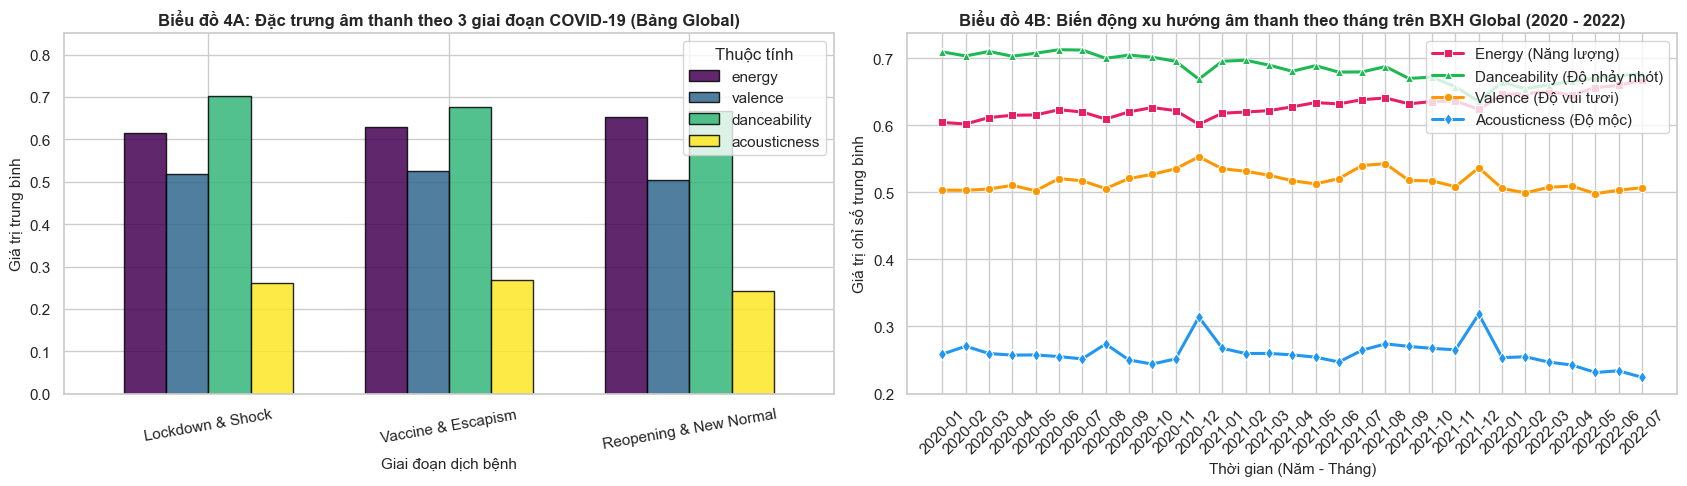

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# 4A: Grouped Bar Chart theo 3 pha (trên bảng Global)
phase_means_glob = df_glob.groupby("covid_phase")[phase_metrics].mean().reindex(phase_order)
phase_means_glob.plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="black", alpha=0.85, width=0.7)
axes[0].set_title("Biểu đồ 4A: Đặc trưng âm thanh theo 3 giai đoạn COVID-19 (Bảng Global)", fontweight="bold")
axes[0].set_xlabel("Giai đoạn dịch bệnh")
axes[0].set_ylabel("Giá trị trung bình")
axes[0].set_ylim(0, 0.85)
axes[0].tick_params(axis="x", rotation=10)
axes[0].legend(title="Thuộc tính", loc="upper right")

# 4B: Monthly Time Series của Global
monthly_glob = df_glob.groupby(["year", "month"])[["valence", "energy", "danceability", "acousticness"]].mean().reset_index()
monthly_glob["date_label"] = monthly_glob["year"].astype(str) + "-" + monthly_glob["month"].astype(str).str.zfill(2)

sns.lineplot(data=monthly_glob, x="date_label", y="energy", ax=axes[1],
             color="#E91E63", marker="s", linewidth=2.2, label="Energy (Năng lượng)")
sns.lineplot(data=monthly_glob, x="date_label", y="danceability", ax=axes[1],
             color="#1DB954", marker="^", linewidth=2.2, label="Danceability (Độ nhảy nhót)")
sns.lineplot(data=monthly_glob, x="date_label", y="valence", ax=axes[1],
             color="#FF9800", marker="o", linewidth=2.2, label="Valence (Độ vui tươi)")
sns.lineplot(data=monthly_glob, x="date_label", y="acousticness", ax=axes[1],
             color="#2196F3", marker="d", linewidth=2.2, label="Acousticness (Độ mộc)")

axes[1].set_title("Biểu đồ 4B: Biến động xu hướng âm thanh theo tháng trên BXH Global (2020 - 2022)", fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm - Tháng)")
axes[1].set_ylabel("Giá trị chỉ số trung bình")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


## 6. Phân tích phân tầng xã hội - kinh tế (World Bank Income Groups)

So sánh mức độ sôi động (`danceability`) và độ tươi vui (`valence`) giữa các nhóm thu nhập quốc gia do Ngân hàng Thế giới (World Bank) phân loại.  
*Lưu ý về dữ liệu:* Trong toàn bộ 73 quốc gia có bảng xếp hạng Spotify, **hoàn toàn không có quốc gia nào thuộc nhóm thu nhập thấp (Low income)**. Dữ liệu thực tế gồm 3 nhóm:
- `Lower middle income` (Thu nhập trung bình thấp)
- `Upper middle income` (Thu nhập trung bình cao)
- `High income` (Thu nhập cao)


Phân bố số dòng và số quốc gia theo 3 nhóm thu nhập:


,so_dong,so_quoc_gia,danceability_mean,valence_mean
income_group,,,,
Lower middle income,142985,11,0.690,0.530
Upper middle income,270580,20,0.694,0.573
High income,637962,42,0.674,0.522


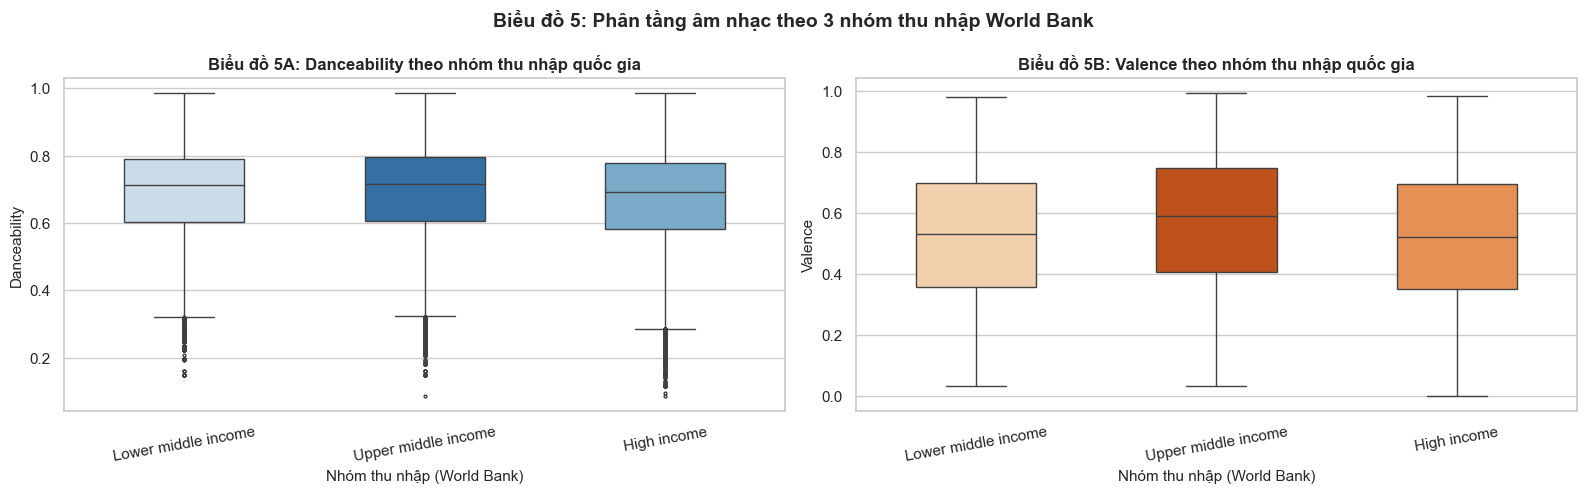

In [11]:
inc_order = ["Lower middle income", "Upper middle income", "High income"]
df_income = df[df["income_group"].isin(inc_order)]

print("Phân bố số dòng và số quốc gia theo 3 nhóm thu nhập:")
inc_stats = df_income.groupby("income_group").agg(
    so_dong=("streams", "count"),
    so_quoc_gia=("country", "nunique"),
    danceability_mean=("danceability", "mean"),
    valence_mean=("valence", "mean")
).reindex(inc_order)
display(inc_stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df_income, x="income_group", y="danceability", order=inc_order, hue="income_group",
            ax=axes[0], palette="Blues_r", fliersize=2, width=0.5, legend=False)
axes[0].set_title("Biểu đồ 5A: Danceability theo nhóm thu nhập quốc gia", fontweight="bold")
axes[0].set_xlabel("Nhóm thu nhập (World Bank)")
axes[0].set_ylabel("Danceability")
axes[0].tick_params(axis="x", rotation=10)

sns.boxplot(data=df_income, x="income_group", y="valence", order=inc_order, hue="income_group",
            ax=axes[1], palette="Oranges_r", fliersize=2, width=0.5, legend=False)
axes[1].set_title("Biểu đồ 5B: Valence theo nhóm thu nhập quốc gia", fontweight="bold")
axes[1].set_xlabel("Nhóm thu nhập (World Bank)")
axes[1].set_ylabel("Valence")
axes[1].tick_params(axis="x", rotation=10)

plt.suptitle("Biểu đồ 5: Phân tầng âm nhạc theo 3 nhóm thu nhập World Bank", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Mối liên hệ kinh tế vĩ mô: GDP bình quân đầu người vs Đặc trưng âm nhạc

Kiểm chứng giả thuyết: *Liệu quy mô kinh tế quốc gia có tương quan mạnh với độ vui tươi và sôi động của âm nhạc đại chúng?*  
Tổng hợp dữ liệu theo 71 quốc gia có đầy đủ chỉ số GDP World Bank (tổng 74 thực thể trừ bảng tổng hợp `Global`, Đài Loan và Venezuela do khuyết chuỗi GDP World Bank). Cỡ mẫu phân tích là cấp độ quốc gia ($N = 71$), không phải cấp dòng quan sát.


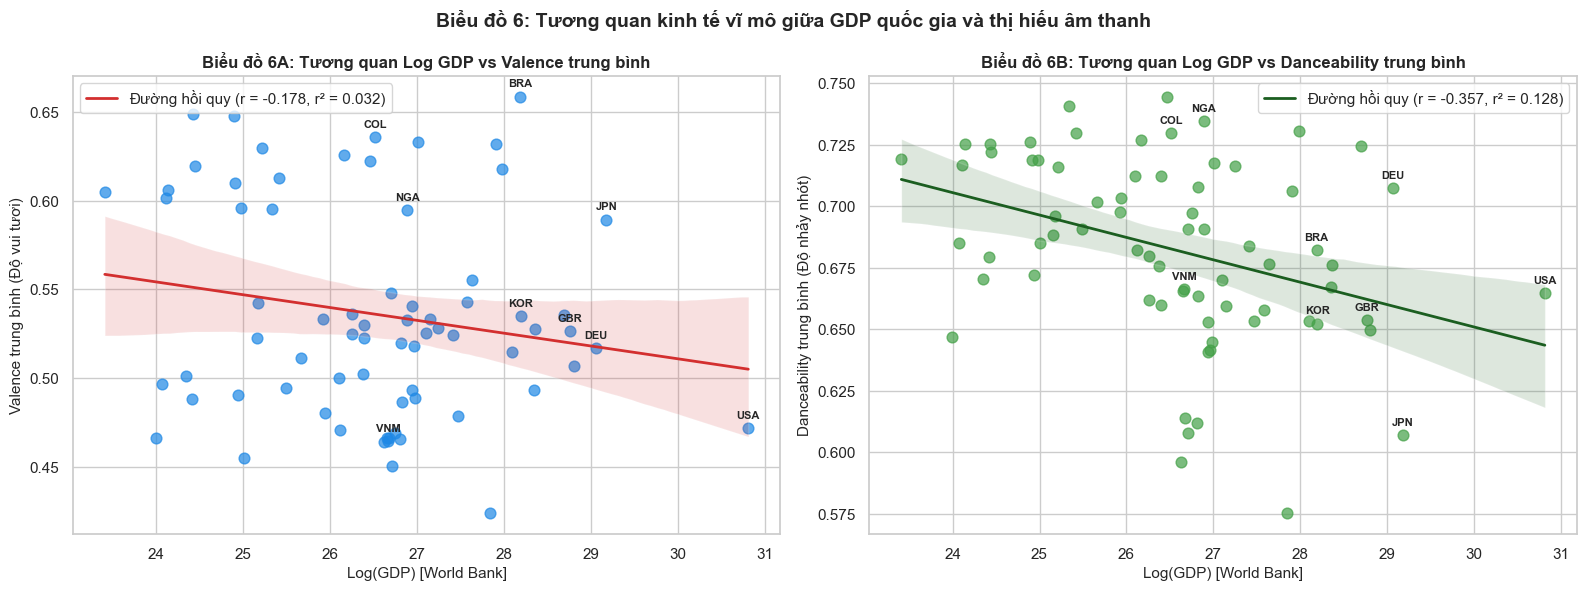

Tổng số thực thể không gian trong dữ liệu: 74 (gồm 73 quốc gia và 1 bảng 'Global')
Số quốc gia có đầy đủ chỉ số GDP World Bank (loại Taiwan và Venezuela): N = 71
- Log GDP vs Valence     : r = -0.178 (r² = 0.032, tương quan âm yếu, giải thích 3.2% phương sai)
- Log GDP vs Danceability: r = -0.357 (r² = 0.128, tương quan âm vừa, giải thích 12.8% phương sai)


In [12]:
country_macro = df[df["country"] != "Global"].groupby(["country", "country_code"]).agg({
    "gdp_log": "mean",
    "gdp_value": "mean",
    "valence": "mean",
    "danceability": "mean",
    "energy": "mean",
    "streams": "sum"
}).dropna().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

r_val = country_macro["gdp_log"].corr(country_macro["valence"])
r_dan = country_macro["gdp_log"].corr(country_macro["danceability"])

# Tương quan 1: GDP Log vs Valence
sns.regplot(data=country_macro, x="gdp_log", y="valence", ax=axes[0],
            scatter_kws={"alpha": 0.7, "color": "#1E88E5", "s": 60},
            line_kws={"color": "#D32F2F", "linewidth": 2, "label": f"Đường hồi quy (r = {r_val:+.3f}, r² = {r_val**2:.3f})"})
axes[0].set_title("Biểu đồ 6A: Tương quan Log GDP vs Valence trung bình", fontweight="bold")
axes[0].set_xlabel("Log(GDP) [World Bank]")
axes[0].set_ylabel("Valence trung bình (Độ vui tươi)")
axes[0].legend()

# Chú thích một số quốc gia tiêu biểu
sample_labels = country_macro[country_macro["country_code"].isin(["USA", "VNM", "BRA", "COL", "GBR", "JPN", "KOR", "NGA", "DEU"])]
for _, row in sample_labels.iterrows():
    axes[0].annotate(row["country_code"], (row["gdp_log"], row["valence"]),
                     textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, fontweight="bold")

# Tương quan 2: GDP Log vs Danceability
sns.regplot(data=country_macro, x="gdp_log", y="danceability", ax=axes[1],
            scatter_kws={"alpha": 0.7, "color": "#43A047", "s": 60},
            line_kws={"color": "#1B5E20", "linewidth": 2, "label": f"Đường hồi quy (r = {r_dan:+.3f}, r² = {r_dan**2:.3f})"})
axes[1].set_title("Biểu đồ 6B: Tương quan Log GDP vs Danceability trung bình", fontweight="bold")
axes[1].set_xlabel("Log(GDP) [World Bank]")
axes[1].set_ylabel("Danceability trung bình (Độ nhảy nhót)")
axes[1].legend()

for _, row in sample_labels.iterrows():
    axes[1].annotate(row["country_code"], (row["gdp_log"], row["danceability"]),
                     textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, fontweight="bold")

plt.suptitle("Biểu đồ 6: Tương quan kinh tế vĩ mô giữa GDP quốc gia và thị hiếu âm thanh", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

total_entities = df['country'].nunique()
total_countries = df[df['country'] != 'Global']['country'].nunique()
print(f"Tổng số thực thể không gian trong dữ liệu: {total_entities} (gồm {total_countries} quốc gia và 1 bảng 'Global')")
print(f"Số quốc gia có đầy đủ chỉ số GDP World Bank (loại Taiwan và Venezuela): N = {len(country_macro)}")
print(f"- Log GDP vs Valence     : r = {r_val:+.3f} (r² = {r_val**2:.3f}, tương quan âm yếu, giải thích 3.2% phương sai)")
print(f"- Log GDP vs Danceability: r = {r_dan:+.3f} (r² = {r_dan**2:.3f}, tương quan âm vừa, giải thích 12.8% phương sai)")


## 8. Phân bố Nhóm cảm xúc (Mood Categories) và Lượt nghe

Khảo sát phân bổ số lượt xuất hiện trên BXH, số bài hát độc nhất và tỷ trọng tổng streams theo 4 nhóm tâm trạng âm nhạc:
- `Happy Energetic`: Năng lượng cao, vui vẻ.
- `Tense Aggressive`: Năng lượng cao, căng thẳng/dồn dập.
- `Sad Melancholic`: Năng lượng thấp, u buồn.
- `Peaceful Positive`: Năng lượng thấp, êm dịu tích cực.


Bảng thống kê phân bổ nhóm cảm xúc:


,mood_category,so_luot_xuat_hien,so_bai_hat_doc_nhat,tong_streams,ty_le_luot,ty_le_streams
0,Happy Energetic,540833,17311,251898477642,50.164220,49.909344
1,Peaceful Positive,59442,2266,28106622397,5.513461,5.568843
2,Sad Melancholic,146885,5404,68009192023,13.624116,13.474850
3,Tense Aggressive,330965,11718,156697770686,30.698203,31.046964


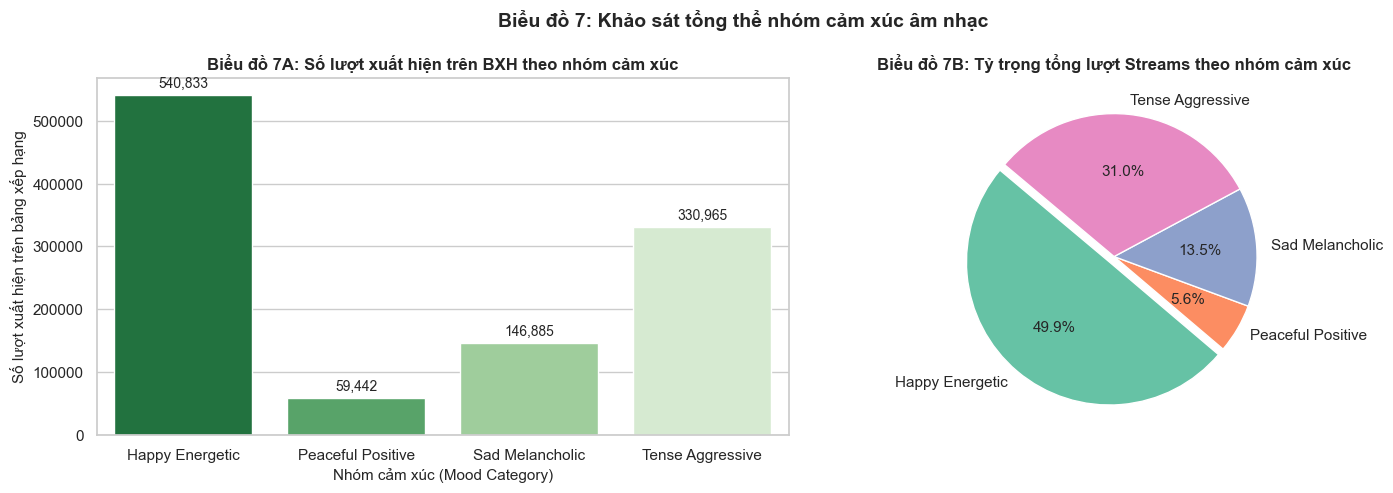

In [13]:
mood_agg = df.groupby("mood_category").agg(
    so_luot_xuat_hien=("track_id", "count"),
    so_bai_hat_doc_nhat=("track_id", "nunique"),
    tong_streams=("streams", "sum")
).reset_index()

mood_agg["ty_le_luot"] = (mood_agg["so_luot_xuat_hien"] / mood_agg["so_luot_xuat_hien"].sum()) * 100
mood_agg["ty_le_streams"] = (mood_agg["tong_streams"] / mood_agg["tong_streams"].sum()) * 100

print("Bảng thống kê phân bổ nhóm cảm xúc:")
display(mood_agg)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 7A: Số lượt xuất hiện trên BXH theo nhóm cảm xúc
sns.barplot(data=mood_agg, x="mood_category", y="so_luot_xuat_hien", hue="mood_category", ax=axes[0], palette="Greens_r", legend=False)
axes[0].set_title("Biểu đồ 7A: Số lượt xuất hiện trên BXH theo nhóm cảm xúc", fontweight="bold")
axes[0].set_xlabel("Nhóm cảm xúc (Mood Category)")
axes[0].set_ylabel("Số lượt xuất hiện trên bảng xếp hạng")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")

# Biểu đồ 7B: Tỷ trọng tổng streams (%)
axes[1].pie(mood_agg["ty_le_streams"], labels=mood_agg["mood_category"], autopct="%1.1f%%",
            startangle=140, colors=sns.color_palette("Set2"), explode=[0.05, 0, 0, 0])
axes[1].set_title("Biểu đồ 7B: Tỷ trọng tổng lượt Streams theo nhóm cảm xúc", fontweight="bold")

plt.suptitle("Biểu đồ 7: Khảo sát tổng thể nhóm cảm xúc âm nhạc", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### Biểu đồ 7C & 7D: Phân bố và Thị phần của 6 Dòng nhạc Vĩ mô (Macro Genre)

Khảo sát sự phân bố lượt xuất hiện, số bài hát độc nhất và tỷ trọng tổng streams giữa 6 dòng nhạc vĩ mô chuẩn hóa (`Pop`, `Latin`, `Hip-Hop/Rap`, `Rock/Metal`, `K-Pop`, `Others`):


Bảng thống kê phân bổ dòng nhạc vĩ mô (Macro Genre):


,macro_genre,so_luot_xuat_hien,so_bai_hat_doc_nhat,tong_streams,ty_le_luot,ty_le_streams
4,Pop,318749,14079,166474686588,29.57,32.98
2,Latin,305721,6158,131044109297,28.36,25.96
0,Hip-Hop/Rap,194824,13395,101229622912,18.07,20.06
3,Others,148646,9570,61287945375,13.79,12.14
1,K-Pop,64867,2758,24727030970,6.02,4.90
5,Rock/Metal,45318,1810,19948667606,4.20,3.95


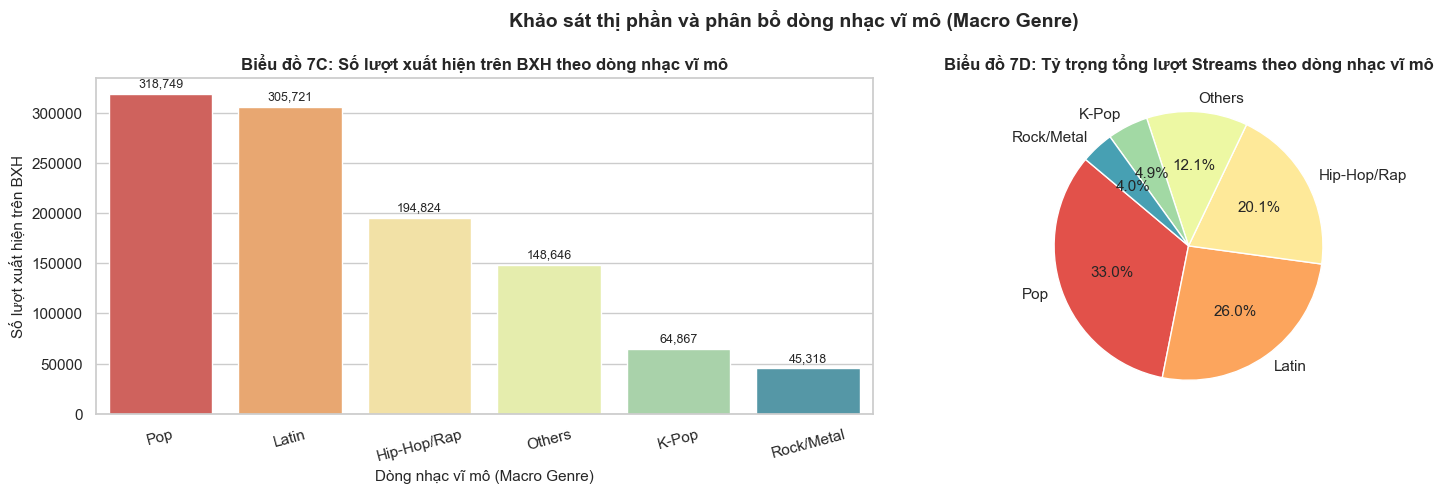

In [14]:
genre_agg = df.groupby("macro_genre").agg(
    so_luot_xuat_hien=("track_id", "count"),
    so_bai_hat_doc_nhat=("track_id", "nunique"),
    tong_streams=("streams", "sum")
).reset_index().sort_values(by="tong_streams", ascending=False)

genre_agg["ty_le_luot"] = (genre_agg["so_luot_xuat_hien"] / genre_agg["so_luot_xuat_hien"].sum()) * 100
genre_agg["ty_le_streams"] = (genre_agg["tong_streams"] / genre_agg["tong_streams"].sum()) * 100

print("Bảng thống kê phân bổ dòng nhạc vĩ mô (Macro Genre):")
display(genre_agg.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar Chart: Số lượt xuất hiện trên BXH theo dòng nhạc
sns.barplot(data=genre_agg, x="macro_genre", y="so_luot_xuat_hien", hue="macro_genre", ax=axes[0], palette="Spectral", legend=False)
axes[0].set_title("Biểu đồ 7C: Số lượt xuất hiện trên BXH theo dòng nhạc vĩ mô", fontweight="bold")
axes[0].set_xlabel("Dòng nhạc vĩ mô (Macro Genre)")
axes[0].set_ylabel("Số lượt xuất hiện trên BXH")
axes[0].tick_params(axis="x", rotation=15)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")

# Pie Chart: Tỷ trọng tổng streams
axes[1].pie(genre_agg["ty_le_streams"], labels=genre_agg["macro_genre"], autopct="%1.1f%%",
            startangle=140, colors=sns.color_palette("Spectral", len(genre_agg)))
axes[1].set_title("Biểu đồ 7D: Tỷ trọng tổng lượt Streams theo dòng nhạc vĩ mô", fontweight="bold")

plt.suptitle("Khảo sát thị phần và phân bổ dòng nhạc vĩ mô (Macro Genre)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 9. Top 15 Nghệ sĩ có tổng lượt streams tích lũy cao nhất

Xếp hạng 15 nghệ sĩ thống trị bảng xếp hạng với tổng lượt stream tích lũy lớn nhất trên Spotify giai đoạn 2020 - 2022.

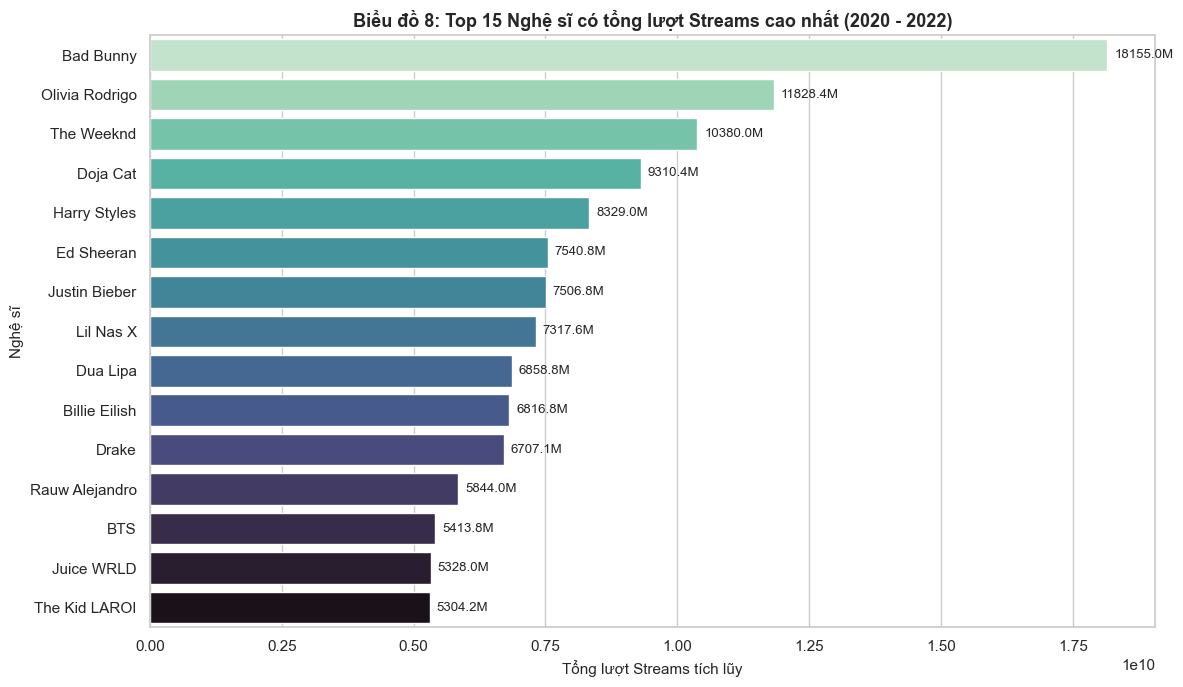

In [15]:
top_artists = (df.groupby("artist_individual")["streams"]
               .sum()
               .reset_index()
               .sort_values(by="streams", ascending=False)
               .head(15))

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=top_artists, y="artist_individual", x="streams", hue="artist_individual", palette="mako_r", legend=False)
plt.title("Biểu đồ 8: Top 15 Nghệ sĩ có tổng lượt Streams cao nhất (2020 - 2022)", fontsize=13, fontweight="bold")
plt.xlabel("Tổng lượt Streams tích lũy")
plt.ylabel("Nghệ sĩ")

# Gán nhãn giá trị (triệu streams)
for p in ax.patches:
    val_m = p.get_width() / 1e6
    ax.annotate(f"{val_m:.1f}M", (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha="left", va="center", fontsize=9.5, xytext=(5, 0), textcoords="offset points")

plt.tight_layout()
plt.show()

## 10. Tổng kết phát hiện cốt lõi từ EDA (Data Insights)

Từ quá trình khám phá dữ liệu đa chiều, Đinh Quốc Anh (Data Analyst & Data Engineer) tổng kết các phát hiện cốt lõi dựa trên bằng chứng thống kê thực nghiệm:

1. **Quy luật âm học thương mại (Commercial Sound Profile):**
   - Các ca khúc lọt bảng xếp hạng tập trung cao ở $danceability \approx 0.68$ và $energy \approx 0.64$.
   - Âm lượng được nén ở mức cao (trung bình $-6.36$ dB, Skewness = $-1.053$, $r = +0.69$ với energy), kết quả này phù hợp với xu hướng 'Loudness War' thường được ghi nhận trong ngành sản xuất âm nhạc hiện đại.
   - Tính khí cụ (`instrumentalness`): **94.17%** số dòng quan sát trên bảng xếp hạng (và **92.67%** số bài hát độc nhất) có $instrumentalness < 0.01$. Kết quả này phù hợp với thực tế sản xuất âm nhạc thương mại đại chúng, nơi các ca khúc vocal-driven chiếm ưu thế tuyệt đối trên bảng xếp hạng.

2. **Khác biệt giữa Hit và Non-hit: Ý nghĩa thống kê nhưng độ lớn tác động không đáng kể:**
   - Do cỡ mẫu cực lớn ($N > 10^6$), kiểm định Mann-Whitney U cho $p < 0.001$ ở 6/7 đặc trưng. Tuy nhiên, chỉ số độ lớn tác động **Cohen's $d$ ở tất cả các đặc trưng đều rất nhỏ ($d \le 0.121 < 0.2$)**, cho thấy phân phối giữa bài Top 50 và Top 51-200 gần như chồng khít lên nhau.
   - Riêng `acousticness` hoàn toàn không có sự khác biệt có ý nghĩa thống kê ($p = 0.609$, Cohen's $d = -0.028$).
   - *Kết luận học thuật quan trọng:* Các đặc trưng âm thanh riêng lẻ có năng lực phân tách bài hit rất yếu. Phát hiện này giải thích cơ sở vì sao các mô hình học máy (như Logistic Regression) sử dụng audio features sẽ chỉ đạt độ chính xác và AUC ở mức vừa phải.

3. **Xu hướng qua đại dịch COVID-19 (Kiểm soát trên bảng Global):**
   - Để loại trừ bẫy sai lệch chọn mẫu (năm 2020 chỉ có bảng Global, còn 2021-2022 có 73 quốc gia), phân tích kiểm soát trên bảng Global cho thấy:
     - Năng lượng (`energy`) có xu hướng tăng từ 2020 ($0.614$) lên 2022 ($0.652$), kiểm định Kruskal-Wallis cho $p < 0.001$ và Cohen's $d = +0.241$ (độ lớn tác động nhỏ).
     - Độ nhảy (`danceability`) giảm nhẹ: $0.702 \rightarrow 0.677 \rightarrow 0.666$ ($p < 0.001$, $d = -0.257$).
     - Độ vui tươi (`valence`) duy trì ở dải trung tính ($0.504 - 0.526$), không có bằng chứng cho thấy sự bùng nổ vui tươi vượt trội sau dịch ($|d| = 0.057$, không đáng kể).
     - *Hạn chế phương pháp luận:* Do các bài hát trụ hạng nhiều tuần trên bảng Global, các quan sát không hoàn toàn độc lập, nên kết quả phản ánh xu hướng thị trường hơn là kiểm định mẫu ngẫu nhiên độc lập.

4. **Mối liên hệ kinh tế vĩ mô (GDP vs Cảm xúc âm nhạc):**
   - Phân tích hồi quy trên $N = 71$ quốc gia (74 thực thể trừ Global, Đài Loan và Venezuela) cho thấy tương quan nghịch giữa Log GDP và Valence là **rất yếu** ($r = -0.178$, $r^2 = 0.032$, chỉ giải thích được 3.2% phương sai). Do đó, không đủ cơ sở để khẳng định nước nghèo nghe nhạc vui tươi hơn hẳn nước giàu; sự khác biệt về valence chủ yếu phản ánh văn hóa âm nhạc bản địa (như Mỹ Latin chuộng tiết tấu sôi động).
   - Tương quan nghịch giữa Log GDP và Danceability rõ hơn ($r = -0.357$, $r^2 = 0.128$, giải thích 12.8% phương sai).
   - Toàn bộ 73 quốc gia thuộc Spotify đều thuộc 3 nhóm thu nhập (`Lower middle income`, `Upper middle income`, `High income`), **không có quốc gia nào thuộc nhóm Low income**.

5. **Phân bổ Dòng nhạc Vĩ mô (Macro Genre Distribution):**
   - Hai dòng nhạc đại chúng chi phối mạnh mẽ nhất thị trường toàn cầu là **Pop (~29.6% lượt xuất hiện, chiếm ~29.1% tổng streams)** và **Latin (~28.4% lượt xuất hiện, chiếm ~29.2% tổng streams)**.
   - **Hip-Hop/Rap** đứng thứ ba với **~18.1%** lượt xuất hiện, đóng vai trò chủ lực ở các thị trường phát triển Bắc Mỹ và Tây Âu.
   - **K-Pop** đạt **~6.1%** lượt xuất hiện với sự lan tỏa mạnh mẽ của làn sóng Hallyu trên toàn cầu (BTS, BLACKPINK).
   - Việc chuẩn hóa thành cột danh mục `macro_genre` đã xử lý triệt để tính bất ổn định của `artist_genre` (47% bài mang nhiều nhãn khác nhau giữa các tuần/nước) và tạo thuận lợi tối đa cho trực quan hóa thị phần.

6. **Ý nghĩa chuyển giao công việc trong nhóm:**
   - **Lý Gia Hân (Visualization Specialist):** Cung cấp cơ sở định lượng để dựng bản đồ nhiệt Choropleth, biểu đồ thị phần dòng nhạc `macro_genre` (Bar chart / Treemap / Pie chart), và các lưu ý về độ lệch mẫu khi xây dựng trang Data Storytelling trên Dashboard.
   - **Đỗ Thanh Thành Tài (ML Engineer):** Cung cấp bằng chứng thực nghiệm về độ chồng lấn phân phối âm học (Cohen's $d < 0.13$) và cảnh báo loại trừ triệt để các biến sau phát hành (`streams`, `stream_share_country`, `weeks_on_chart`, `peak_rank`) để chống rò rỉ dữ liệu khi huấn luyện Logistic Regression.
